In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import h5py

from pyoculus.fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot

In [2]:
results_dir = Path("num_results_loc/computed_manifolds")

configs = list(range(11, 20)) + list(range(110, 139)) + [21, 22, 23]

parameters = {}

for config_id in configs:

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)

In [3]:
temperature_dir = Path("num_results_loc/FaADE")

def plot_temperature(config_id, ax, t_f=0.01, k_value=10.0, nx=201, cmap="seismic", alpha=1.0, vmin=None, vmax=None):
    """
    Plot the 2D temperature field on the (x, y) plane.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axis on which to plot the temperature field.
    params : dict
        Configuration parameters.
    t_f : float
        Final simulation time.
    k_value : float
        Exponent defining kappa_perp/kappa_parallel = 10^(-k).
    nx : int
        Spatial resolution.
    cmap : str
        Temperature colormap.
    alpha : float
        Opacity of the temperature field.
    vmin, vmax : float, optional
        Lower and upper limits of the color scale.
    """

    params=parameters[config_id]

    delta1 = params["delta1"]
    delta2 = params["delta2"]
    iota = params["iota_prime"]

    filename = (
        f"2I_k{k_value}_tf{t_f}_"
        f"d{delta1}_{delta2}_res{nx}_"
        f"m1_dT_iota{float(iota)}_Neumann.jld2"
    )

    path = temperature_dir / filename

    if not path.exists():
        print(f"Temperature file not found: {filename}")
        return None

    with h5py.File(path, "r") as f:
        soln = f["soln"]

        # Dereference u to obtain the array of solutions
        u = f[soln["u"]]

        # Access the second solution and dereference it
        T = np.asarray(f[u[1]]).squeeze()

    # Assuming T.shape = (ny, nx)
    ny, nx_T = T.shape

    x = np.linspace(0, 2, nx_T)
    y = np.linspace(0, 2*np.pi, ny)

    # Plot the temperature field
    pcm = ax.pcolormesh(x, y, T, cmap=cmap, shading="auto", alpha=alpha, vmin=vmin, vmax=vmax, zorder=0)

    # Colorbar
    cbar = ax.figure.colorbar(pcm, ax=ax)
    cbar.set_label(r"$T(x,y)$")

    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2*np.pi)

    return pcm


In [4]:
def plot_configurations_T(config_ids, ncols=3, figsize_per_subplot=(5, 4),
                        t_f=0.01, k_value=10.0, cmap="seismic",
                        save_name=None, sharey=True):

    n = len(config_ids)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_subplot[0] * ncols, figsize_per_subplot[1] * nrows),
                             squeeze=False, sharex=True, sharey=sharey)

    for ax, config_id in zip(axes.flat, config_ids):
        plot_temperature(config_id, ax=ax, t_f=t_f, k_value=k_value, cmap=cmap)

    # Hide unused subplots
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)

    # Shared legend
    handles, labels = axes.flat[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.01),
                   ncol=len(handles), title="Parallel transport",
                   fontsize=10, title_fontsize=11, frameon=True)

    fig.tight_layout(rect=[0, 0.09, 1, 1])

    if save_name is not None:
        save_dir = Path("Figures/comparisons")
        save_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_dir / f"{save_name}.png", dpi=300, bbox_inches="tight")

    return fig, axes

Temperature file not found: 2I_k12.0_tf0.2_d0.05_0.05_res201_m1_dT_iota4.0_Neumann.jld2


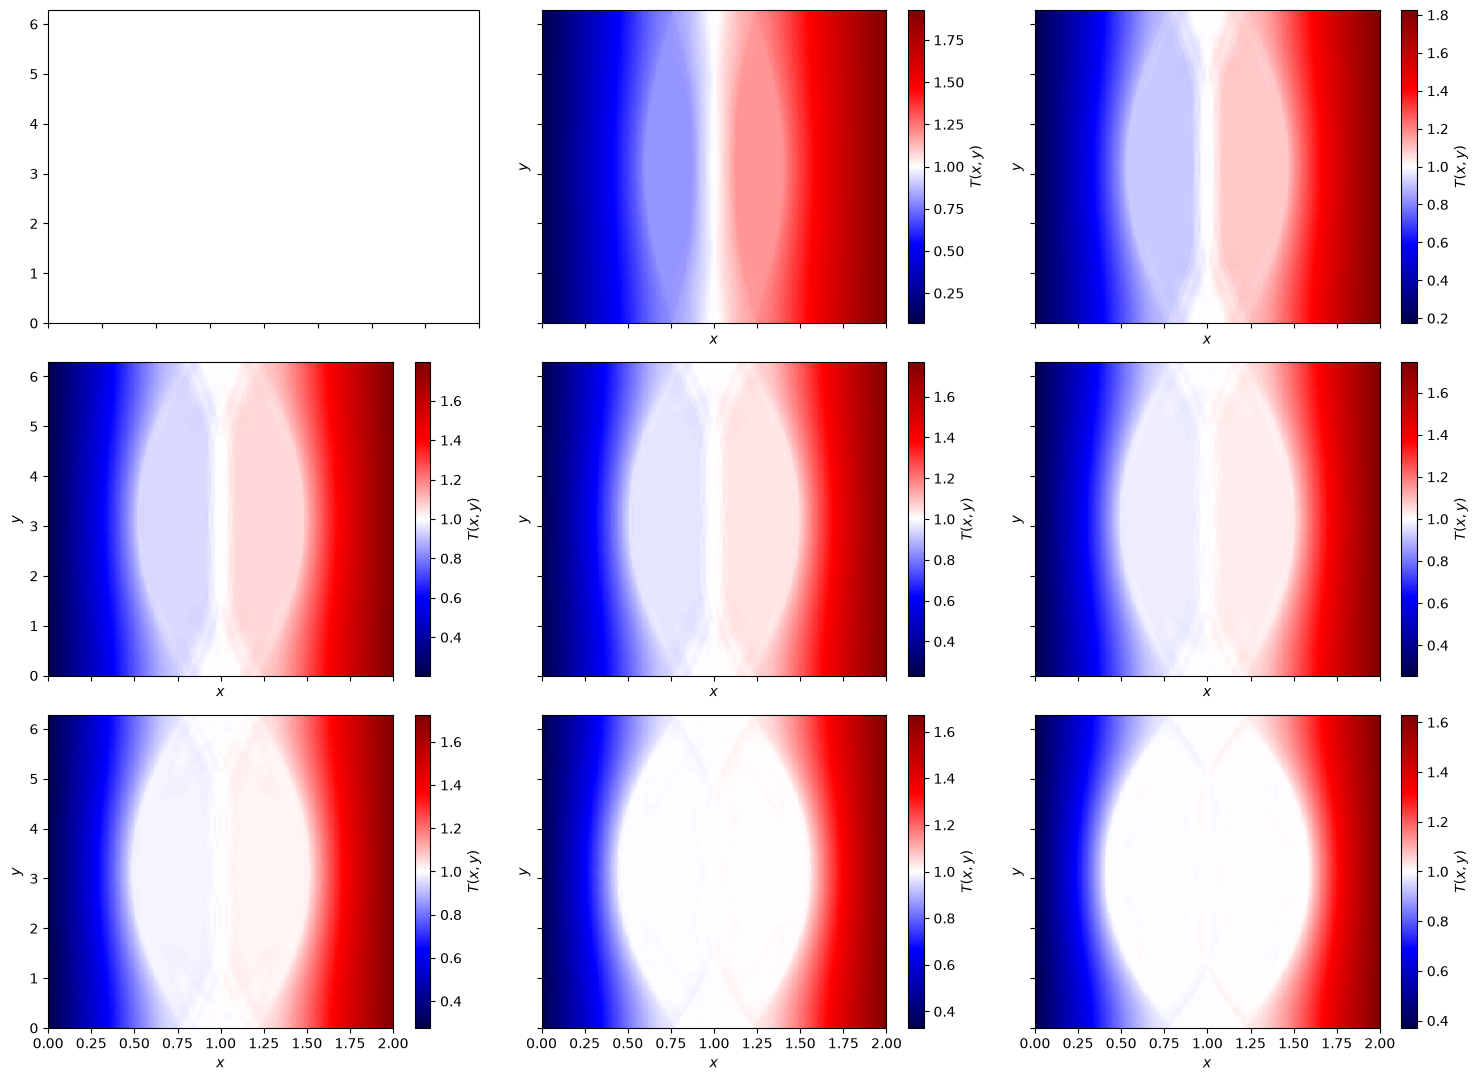

In [11]:
configs_2 = [115, 114, 113, 129, 130, 131, 117, 116, 13]
t_f = 0.2

fig, ax = plot_configurations_T(configs_2, ncols=3, t_f=t_f, save_name=f"2D_T_tf{t_f}_iota4.0", k_value=12.0)

plt.show()

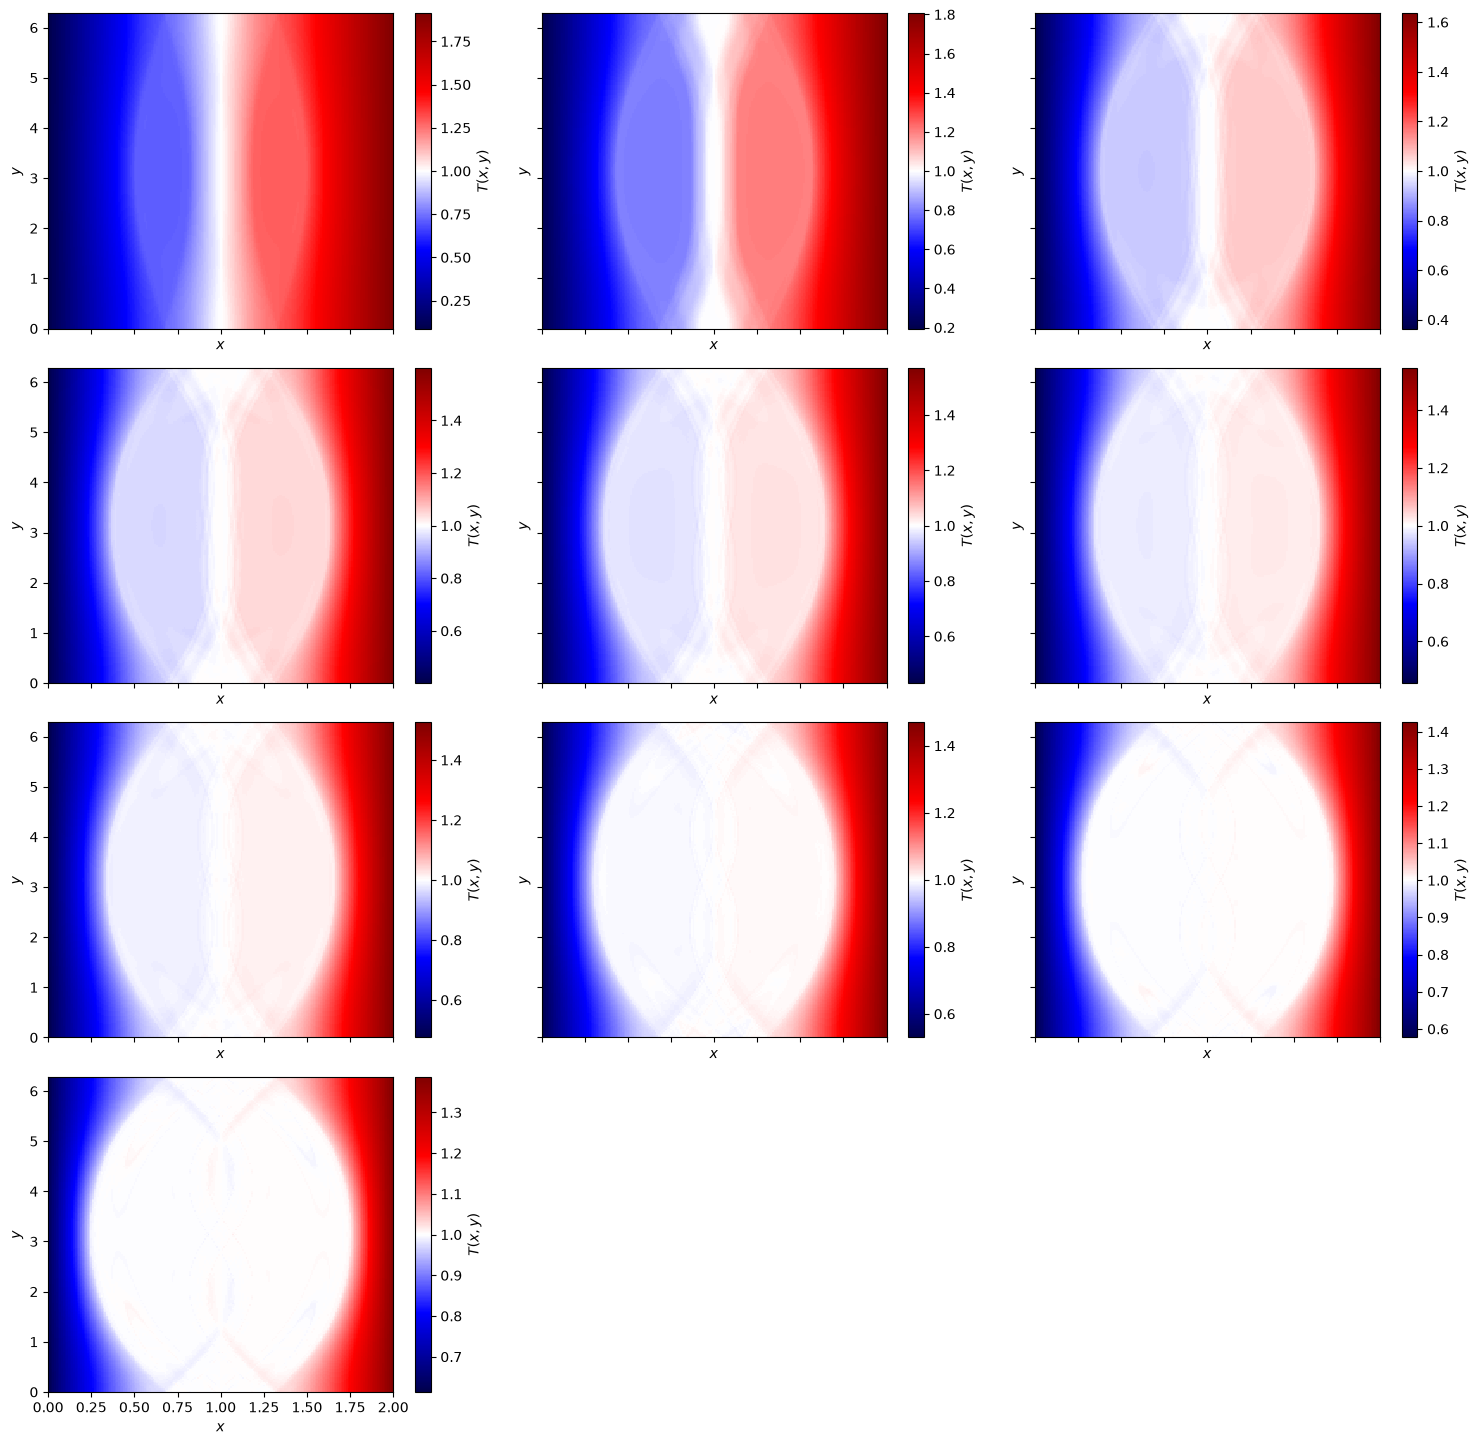

In [16]:
configs_3 = [119, 118, 122, 132, 133, 134, 123, 18, 120, 121] 
t_f = 0.2

fig, ax = plot_configurations_T(configs_3, ncols=3, t_f=t_f, save_name=f"2D_T_tf{t_f}_iota3.0", k_value=10.0)

plt.show()

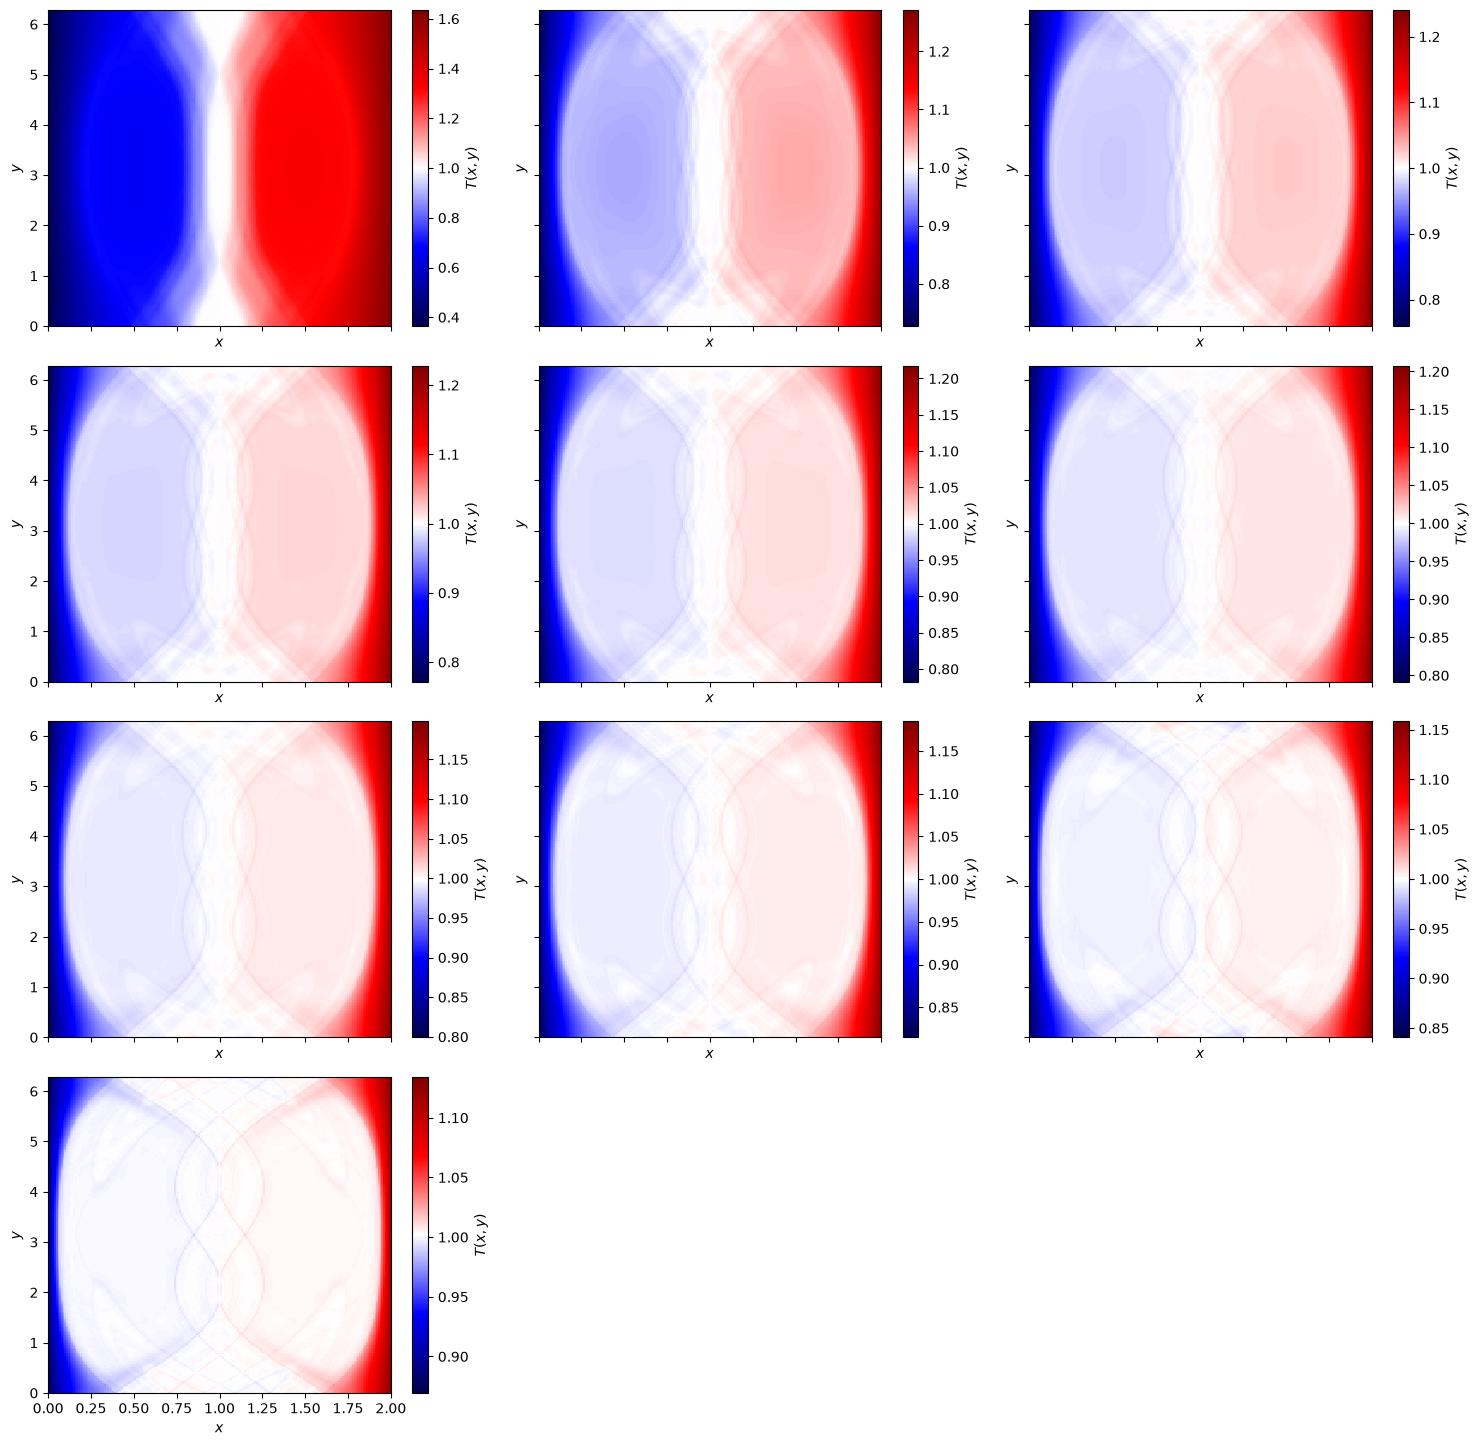

In [17]:
configs_4 = [124, 12, 135, 136, 125, 137, 138, 126, 127, 128] 
t_f = 0.2

fig, ax = plot_configurations_T(configs_4, ncols=3, t_f=t_f, save_name=f"2D_T_tf{t_f}_iota2.0", k_value=10.0)

plt.show()